# 01 · ¿Dónde se cultiva hoy el cempasúchil?

El mapa actual de la flor. Usamos el **promedio de 2021 a 2025** para que un año malo (2025 fue más bajo) no distorsione el ranking, y la **superficie sembrada** porque es la única medida que suma las cuatro presentaciones.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

estatal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_estatal.csv")
municipal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_municipal.csv")
FUENTE_SIAP = "Fuente: SIAP, Cierre de la Producción Agrícola 1980-2025. Análisis: Sahuaris."

In [2]:
ANIOS = range(2021, 2026)
reciente = estatal[estatal["anio"].isin(ANIOS)]
ha_estado = (reciente.groupby("nomestado")["sembrada"].sum() / len(ANIOS)).sort_values(ascending=False)
participacion = (ha_estado / ha_estado.sum() * 100).round(1)
tabla = pd.DataFrame({"ha_promedio": ha_estado.round(1), "pct": participacion, "pct_acumulado": participacion.cumsum().round(1)})
print(f"Superficie nacional promedio 2021-2025: {ha_estado.sum():,.0f} ha en {len(ha_estado)} estados")
tabla

Superficie nacional promedio 2021-2025: 2,227 ha en 15 estados


,ha_promedio,pct,pct_acumulado
nomestado,,,
Puebla,1480.1,66.5,66.5
Hidalgo,113.0,5.1,71.6
San Luis Potosí,96.4,4.3,75.9
México,92.8,4.2,80.1
Tlaxcala,91.3,4.1,84.2
Oaxaca,90.4,4.1,88.3
Guerrero,85.3,3.8,92.1
Michoacán,50.4,2.3,94.4
Morelos,45.7,2.1,96.5


## Superficie por estado

Interactiva: outputs/figuras/01_estados_hectareas.html


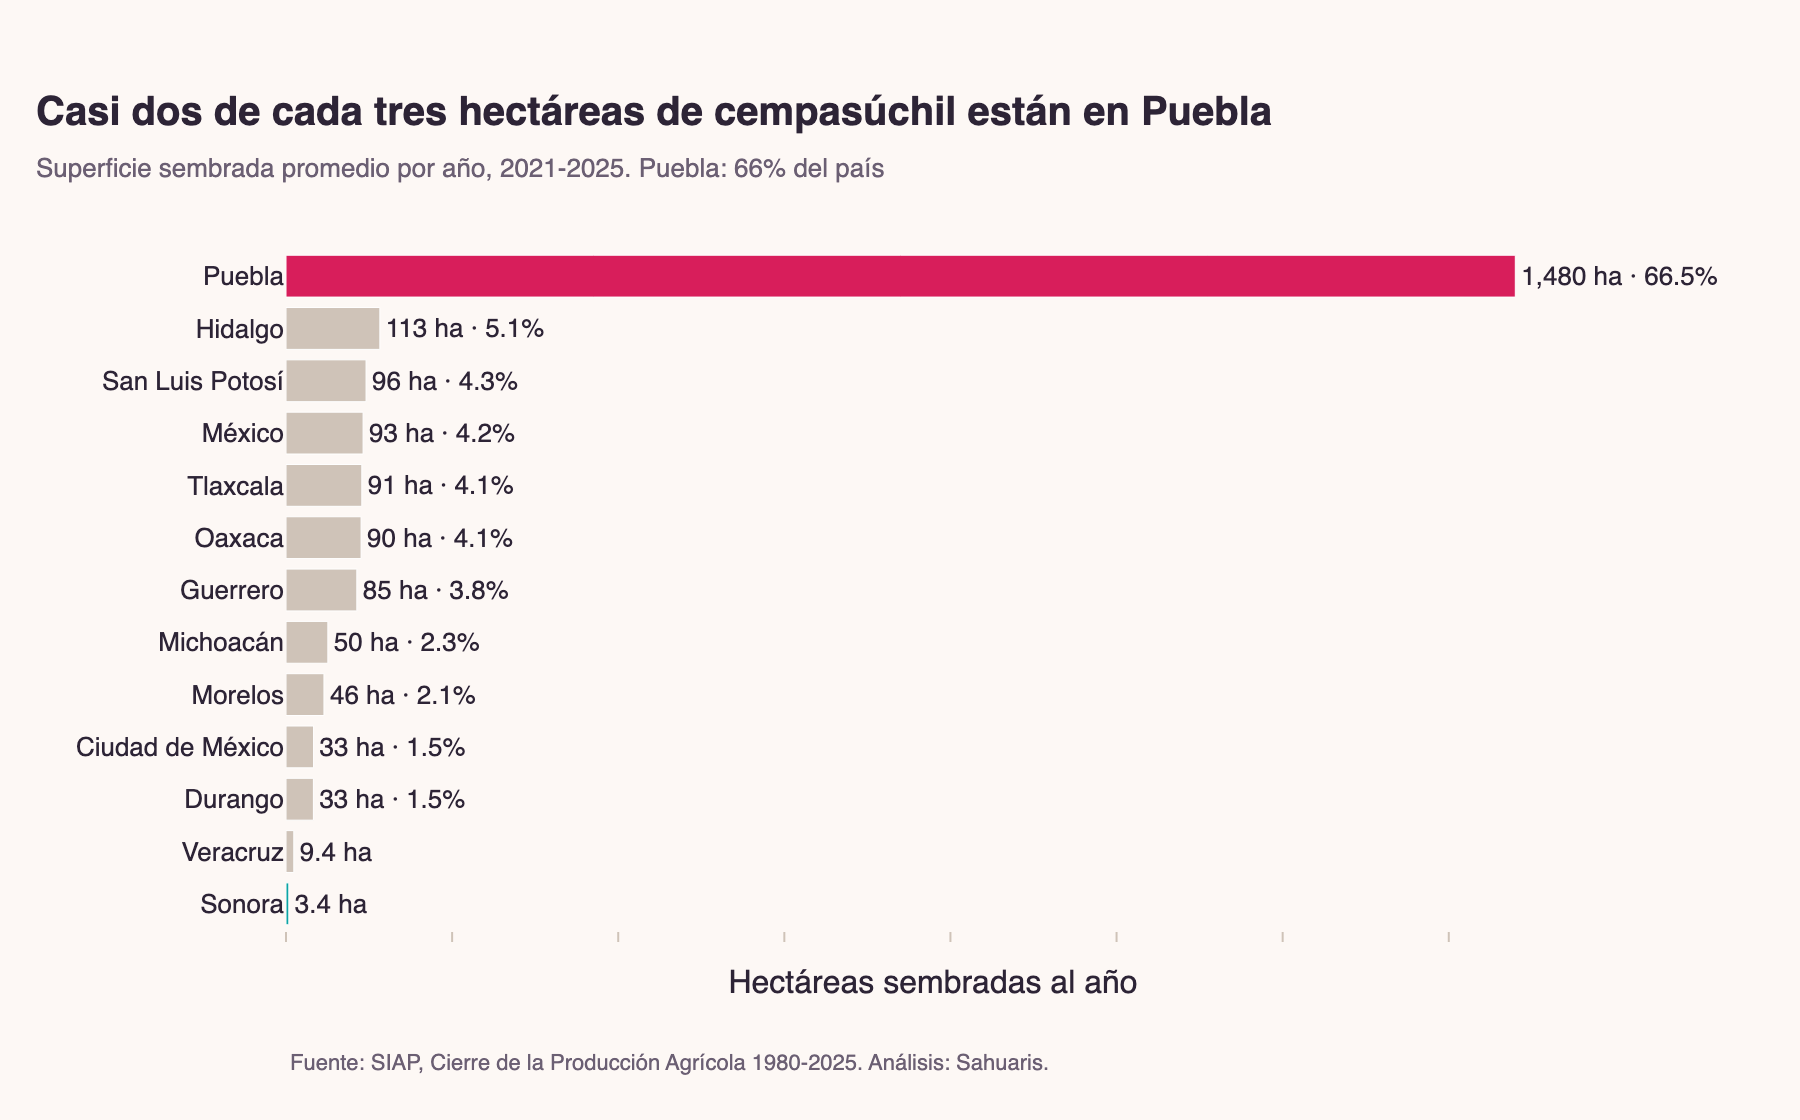

In [3]:
top = tabla.head(12).iloc[::-1]
if "Sonora" not in top.index:
    top = pd.concat([tabla.loc[["Sonora"]], top])
colores = [tema.PROTAGONISTA if e == "Puebla" else tema.SECUNDARIO if e == "Sonora" else tema.NEUTRO for e in top.index]
fig = go.Figure(go.Bar(
    x=top["ha_promedio"], y=top.index, orientation="h", marker_color=colores,
    text=[f"{v:,.0f} ha · {p:.1f}%" if v >= 10 else f"{v:,.1f} ha" for v, p in zip(top["ha_promedio"], top["pct"])],
    textposition="outside", cliponaxis=False,
    hovertemplate="%{y}: %{x:,.1f} ha al año<extra></extra>",
))
puebla = tabla.loc["Puebla"]
fig.update_layout(
    title=tema.titulo("Casi dos de cada tres hectáreas de cempasúchil están en Puebla",
                      f"Superficie sembrada promedio por año, 2021-2025. Puebla: {puebla['pct']:.0f}% del país"),
    xaxis=dict(title="Hectáreas sembradas al año", showticklabels=False), yaxis=dict(title=""),
    height=560, margin=dict(r=110),
)
tema.nota_fuente(fig, FUENTE_SIAP)
tema.mostrar(fig, "01_estados_hectareas", alto=560)

## Las tres formas de llegar al altar

Cada estado se especializa: Puebla vende flor a granel, CDMX y el Estado de México venden plantas en maceta, y Michoacán y el Estado de México venden manojos.

In [4]:
prod = (reciente.groupby(["presentacion", "nomestado"])["volumenproduccion"].sum() / len(ANIOS)).reset_index()
prod["pct"] = prod.groupby("presentacion")["volumenproduccion"].transform(lambda s: s / s.sum() * 100)
lideres = prod.sort_values("volumenproduccion", ascending=False).groupby("presentacion").head(3)
lideres.assign(volumenproduccion=lideres["volumenproduccion"].round(0), pct=lideres["pct"].round(1)).sort_values(["presentacion", "pct"], ascending=[True, False])

,presentacion,nomestado,volumenproduccion,pct
5,Flor a granel (t),Puebla,14025.0,73.5
2,Flor a granel (t),Hidalgo,1216.0,6.4
6,Flor a granel (t),San Luis Potosí,898.0,4.7
12,Flor en manojo,Michoacán,268900.0,54.9
13,Flor en manojo,México,132345.0,27.0
14,Flor en manojo,Puebla,32734.0,6.7
16,Planta en maceta,Ciudad de México,1317964.0,60.6
17,Planta en maceta,México,855365.0,39.4


## Municipios: la flor se concentra todavía más

In [5]:
mun_rec = municipal[municipal["anio"].isin(ANIOS)]
ha_mun = (mun_rec.groupby(["nomestado", "nommunicipio"])["sembrada"].sum() / len(ANIOS)).sort_values(ascending=False)
ha_mun_pct = (ha_mun / ha_mun.sum() * 100).round(1)
print(f"{len(ha_mun)} municipios sembraron cempasúchil al menos un año entre 2021 y 2025")
print(f"Los 10 primeros suman {ha_mun_pct.head(10).sum():.0f}% de la superficie")
pd.DataFrame({"ha_promedio": ha_mun.round(1), "pct": ha_mun_pct}).head(15)

133 municipios sembraron cempasúchil al menos un año entre 2021 y 2025
Los 10 primeros suman 45% de la superficie


ha_promedio   pct
nomestado nommunicipio                                       
Puebla    Atlixco                                 353.5  15.9
          Palmar de Bravo                         138.0   6.2
          Tianguismanalco                         123.8   5.6
Guerrero  Tixtla de Guerrero                       67.0   3.0
Puebla    Huaquechula                              61.6   2.8
          Santa Isabel Cholula                     60.0   2.7
          Quecholac                                53.4   2.4
Hidalgo   Tula de Allende                          50.7   2.3
Puebla    Huejotzingo                              50.1   2.2
          San Jerónimo Tecuanipan                  48.6   2.2
          San Pedro Cholula                        46.7   2.1
          Tecamachalco                             45.4   2.0
          Tepeaca                                  38.0   1.7
Tlaxcala  Ixtacuixtla de Mariano Matamoros         34.8   1.6
Durango   Lerdo                                    33.0   1.5

In [6]:
tabla.to_csv(config.DIR_PROCESSED / "hectareas_por_estado_2021_2025.csv")